# CUB-200-2011 — Exploratory Data Analysis (EDA)

## Objective
Explore the CUB-200-2011 bird image dataset before preprocessing and model development. This notebook checks dataset structure, class distribution, image dimensions, data quality, and available descriptions.

**Dataset source:** Hugging Face — `Multimodal-Fatima/CUB_train` and `Multimodal-Fatima/CUB_test`

## 1. Import libraries

Import the tools used to load, inspect, analyze, and visualize the dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset
from PIL import Image
import hashlib
from io import BytesIO

RANDOM_STATE = 42

print("Imports completed successfully.")

c:\Users\Hager\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports completed successfully.


## 2. Load the dataset

Load the training and test splits from Hugging Face. If these datasets are already cached locally, they may load without downloading again.

In [2]:
train_data = load_dataset(
    "Multimodal-Fatima/CUB_train",
    split="train"
)

test_data = load_dataset(
    "Multimodal-Fatima/CUB_test",
    split="test"
)

print(f"Training images: {len(train_data):,}")
print(f"Test images: {len(test_data):,}")

Training images: 5,994
Test images: 5,794


## 3. Dataset overview

Check the number of samples, available fields, and whether the expected metadata is present.

In [3]:
overview = pd.DataFrame({
    "Split": ["Train", "Test"],
    "Number of images": [len(train_data), len(test_data)],
    "Number of columns": [len(train_data.column_names), len(test_data.column_names)]
})
display(overview)

required_columns = {"image", "description", "label", "file_name", "id"}
print("Missing train columns:", required_columns - set(train_data.column_names))
print("Missing test columns:", required_columns - set(test_data.column_names))

,Split,Number of images,Number of columns
0,Train,5994,5
1,Test,5794,5


Missing train columns: set()
Missing test columns: set()


## 4. Inspect one sample

Display a sample bird image and its available metadata.

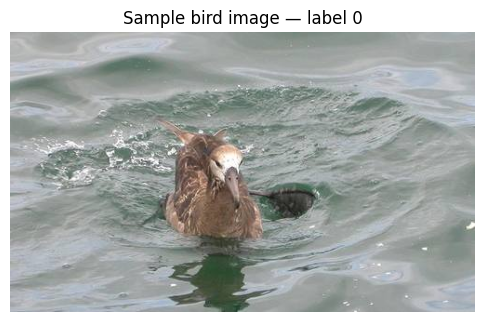

Label: 0
File name: Black_Footed_Albatross_0007_796138.jpg
ID: 0
Description: this bird is brown with a lighter brown crest.
aquatic large bird with long hooked bill, white face, and brown body.
bird has brown body feathers, brown breast feathers, and brown beak
this bird has a white superciliary and brown all around its body with a long bill
this is a brown bird with a white face and a long downward pointing beak.
this bird is brown with white and has a long, pointy beak.
brown duck playing on the lake making a poodle
this bird has wings that are brown and has a long bill
this bird has long brown bill, with a brown body.
this is a medium sized brown bird, with a long pointed bill.



In [4]:
sample = train_data[0]

plt.figure(figsize=(6, 5))
plt.imshow(sample["image"].convert("RGB"))
plt.title(f"Sample bird image — label {sample['label']}")
plt.axis("off")
plt.show()

print("Label:", sample["label"])
print("File name:", sample["file_name"])
print("ID:", sample["id"])
print("Description:", sample["description"])

## 5. Class distribution

Count the images belonging to each label in the training and test splits, then visualize the training class distribution.

Number of training classes: 200
Number of test classes: 200
Training images per class — min: 29
Training images per class — max: 30
Training images per class — mean: 29.97
Training images per class — median: 30.0


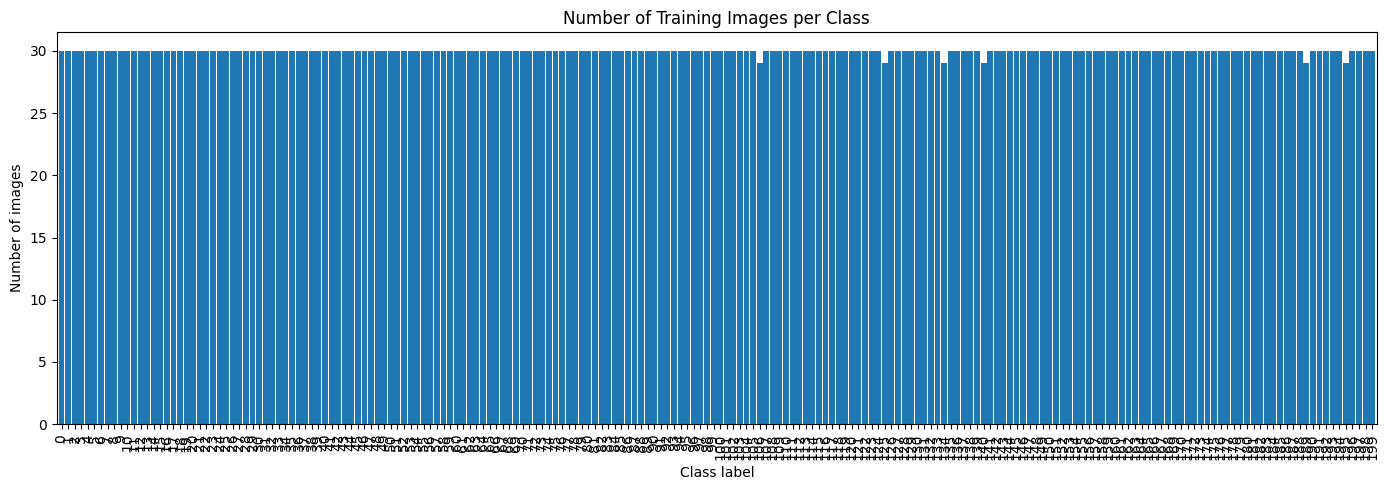

In [5]:
train_labels = np.asarray(train_data["label"], dtype=int)
test_labels = np.asarray(test_data["label"], dtype=int)

train_class_counts = pd.Series(train_labels).value_counts().sort_index()
test_class_counts = pd.Series(test_labels).value_counts().sort_index()

print("Number of training classes:", train_class_counts.size)
print("Number of test classes:", test_class_counts.size)
print("Training images per class — min:", train_class_counts.min())
print("Training images per class — max:", train_class_counts.max())
print("Training images per class — mean:", round(train_class_counts.mean(), 2))
print("Training images per class — median:", train_class_counts.median())

plt.figure(figsize=(14, 5))
train_class_counts.plot(kind="bar", width=0.9)
plt.title("Number of Training Images per Class")
plt.xlabel("Class label")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

## 6. Check missing metadata

Check whether labels, descriptions, filenames, and IDs are missing. An empty description is not necessarily a missing image or label, so each field is reported separately.

In [6]:
def missing_value_summary(dataset, split_name):
    summary = {}
    for column in ["label", "description", "file_name", "id"]:
        values = dataset[column]
        summary[column] = sum(value is None for value in values)
    return {"Split": split_name, **summary}

missing_summary = pd.DataFrame([
    missing_value_summary(train_data, "Train"),
    missing_value_summary(test_data, "Test")
])
display(missing_summary)

,Split,label,description,file_name,id
0,Train,0,0,0,0
1,Test,0,0,0,0


## 7. Image dimensions

Inspect image widths and heights to understand the variation in original image sizes.

Total images inspected: 11788
Unique image dimensions: 1152
Minimum width: 121
Maximum width: 500
Minimum height: 120
Maximum height: 500


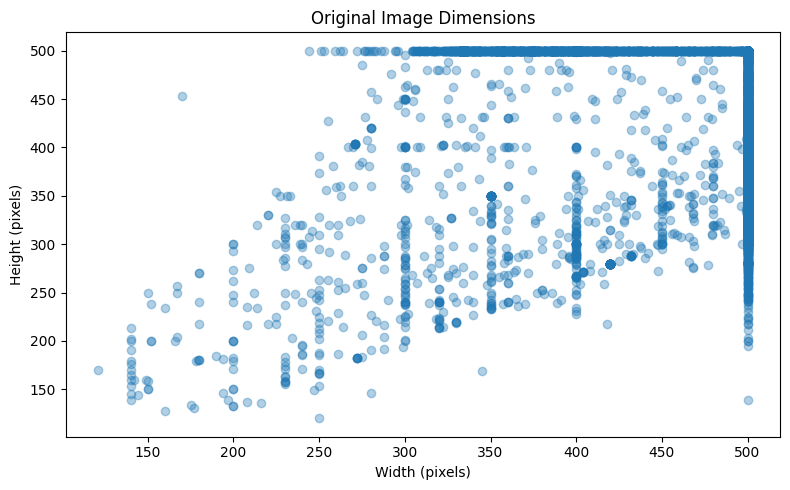

In [7]:
def get_image_size(image):
    return image.size  # (width, height)

# Inspect dimensions for all images in both splits
train_sizes = [get_image_size(image) for image in train_data["image"]]
test_sizes = [get_image_size(image) for image in test_data["image"]]
all_sizes = train_sizes + test_sizes

widths = [size[0] for size in all_sizes]
heights = [size[1] for size in all_sizes]

print("Total images inspected:", len(all_sizes))
print("Unique image dimensions:", len(set(all_sizes)))
print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

plt.figure(figsize=(8, 5))
plt.scatter(widths, heights, alpha=0.35)
plt.title("Original Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

## 8. Image quality checks

Try opening each image and count any images that cannot be read. This check can take some time because it inspects all images.

In [8]:
def count_unreadable_images(dataset, split_name):
    unreadable = []
    for index, image in enumerate(dataset["image"]):
        try:
            image.convert("RGB").load()
        except Exception as error:
            unreadable.append((index, str(error)))
    print(f"{split_name} unreadable images: {len(unreadable)}")
    return unreadable

train_unreadable = count_unreadable_images(train_data, "Train")
test_unreadable = count_unreadable_images(test_data, "Test")

print("Total unreadable images:", len(train_unreadable) + len(test_unreadable))

Train unreadable images: 0
Test unreadable images: 0
Total unreadable images: 0


## 9. Check exact duplicate images

Calculate a SHA-256 hash from each image's pixel content. Matching hashes identify images with identical pixel data. This can take time on the full dataset.

In [9]:
def image_pixel_hash(image):
    image = image.convert("RGB")
    payload = f"{image.size[0]}x{image.size[1]}".encode() + image.tobytes()
    return hashlib.sha256(payload).hexdigest()

image_records = []
for split_name, dataset in [("train", train_data), ("test", test_data)]:
    for index, sample in enumerate(dataset):
        image_records.append({
            "split": split_name,
            "index": index,
            "file_name": sample["file_name"],
            "label": int(sample["label"]),
            "size": sample["image"].size,
            "pixel_hash": image_pixel_hash(sample["image"])
        })

image_info = pd.DataFrame(image_records)
duplicate_mask = image_info.duplicated(subset="pixel_hash", keep=False)
duplicates = image_info[duplicate_mask].sort_values("pixel_hash")

print("Images checked:", len(image_info))
print("Rows belonging to duplicate groups:", int(duplicate_mask.sum()))
if duplicates.empty:
    print("No exact duplicate images found.")
else:
    display(duplicates[["split", "file_name", "label", "size", "pixel_hash"]])

Images checked: 11788
Rows belonging to duplicate groups: 2


,split,file_name,label,size,pixel_hash
1712,train,Pigeon_Guillemot_0018_40195.jpg,57,"(500, 333)",19b05bc693fb22adf2f7a588515855682449ca50b37e39...
1731,train,Pigeon_Guillemot_0081_40339.jpg,57,"(500, 333)",19b05bc693fb22adf2f7a588515855682449ca50b37e39...


## 10. Description / caption overview

Inspect the text descriptions available in the dataset. This section reports missing descriptions and their character lengths; it does not evaluate the semantic quality of the descriptions.

Train descriptions with zero characters: 0
Test descriptions with zero characters: 0
Average train description length: 783.61
Average test description length: 782.66


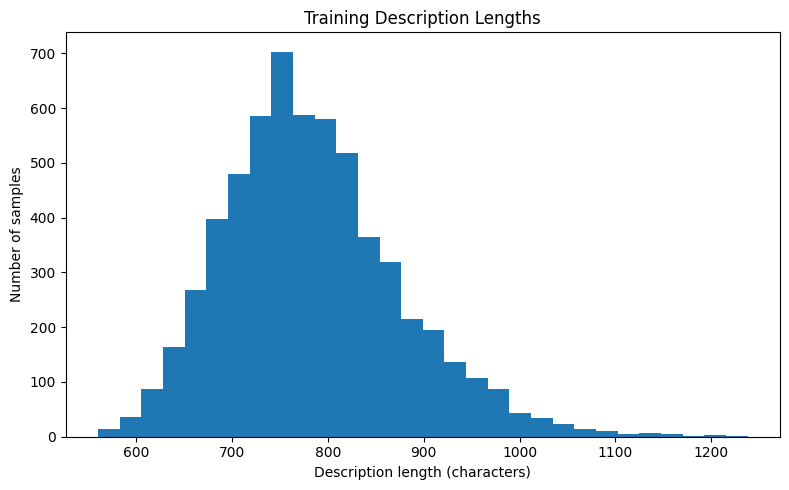

In [10]:
def description_lengths(dataset):
    lengths = []
    for description in dataset["description"]:
        if isinstance(description, str):
            lengths.append(len(description.strip()))
        else:
            lengths.append(0)
    return np.asarray(lengths)

train_description_lengths = description_lengths(train_data)
test_description_lengths = description_lengths(test_data)

print("Train descriptions with zero characters:", int((train_description_lengths == 0).sum()))
print("Test descriptions with zero characters:", int((test_description_lengths == 0).sum()))
print("Average train description length:", round(float(train_description_lengths.mean()), 2))
print("Average test description length:", round(float(test_description_lengths.mean()), 2))

plt.figure(figsize=(8, 5))
plt.hist(train_description_lengths, bins=30)
plt.title("Training Description Lengths")
plt.xlabel("Description length (characters)")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

## 11. EDA summary

Use the output values from the cells above to describe the dataset. The summary below is calculated from the loaded data rather than relying on hard-coded statistics.

In [11]:
print("EDA SUMMARY")
print("=" * 40)
print(f"Total images: {len(train_data) + len(test_data):,}")
print(f"Training images: {len(train_data):,}")
print(f"Test images: {len(test_data):,}")
print(f"Training classes: {len(train_class_counts)}")
print(f"Test classes: {len(test_class_counts)}")
print(f"Unique original dimensions: {len(set(all_sizes))}")
print(f"Unreadable images: {len(train_unreadable) + len(test_unreadable)}")
print(f"Duplicate image rows: {int(duplicate_mask.sum())}")
print(f"Training descriptions with zero characters: {int((train_description_lengths == 0).sum())}")
print()
print("Conclusion:")
print(
    "The EDA examined the dataset structure, class distribution, original image dimensions, "
    "image readability, exact pixel duplicates, and available descriptions. "
    "These findings provide a basis for the preprocessing stage and later CNN development."
)

EDA SUMMARY
Total images: 11,788
Training images: 5,994
Test images: 5,794
Training classes: 200
Test classes: 200
Unique original dimensions: 1152
Unreadable images: 0
Duplicate image rows: 2
Training descriptions with zero characters: 0

Conclusion:
The EDA examined the dataset structure, class distribution, original image dimensions, image readability, exact pixel duplicates, and available descriptions. These findings provide a basis for the preprocessing stage and later CNN development.
